# U03 — Independent information pool, supplied upfront

**Batch:** all 20 cases in the frozen U02 cohort. Generate a candidate-information pool from the original task only, then provide the entire pool with the original RAID AI answer to the frozen U02 rewrite controller. No NGID extractor, eight-word search, source-coverage controller, or controlled disclosure is involved in this experiment.

Three supported arms: `BASELINE`, `DIRECT_PROMPT`, `INFO_POOL`. Default: run only `INFO_POOL` for all 20 cases; add the other arms in configuration for matched comparisons. All use FULL history, the original UQ policy, T=1 sampling and a **10-rewind cap**, followed by original U02 greedy completion. Previous 24-rewind outputs are not matched baselines.

Pool generation is greedy with the same loaded Llama model and cached separately. A pool contains **unverified candidate assertions**, not established facts. It may lack information or hallucinate. Inspect the pool and output before interpreting surprisal; no correctness or coverage score is fabricated. The pool follows the task’s genre: factual details, explanations, procedures, arguments, or explicitly fictional possibilities. Paired human text never enters either prompt.

Place this notebook in the repository's `experiments/` directory. Run cells in order in a fresh kernel. Setup loads the existing U02 machinery; the pool cell and rewrite cell are separate. Results go to a new directory. Qwen highlighting is a final CPU-only cell and never regenerates text. Code checks were performed without executing model inference.

This version regenerates pools under the genre-neutral prompt in a new results directory; it does not mix in the earlier book-pilot caches. No model review pass is included. Aggregate U02 human bands remain active; subject-specific human reference text is never supplied to either generation call.


In [1]:
# ============================================================
# 0. Load the exact frozen U02 machinery as a library
# ============================================================

from pathlib import Path
import ast, copy, gc, hashlib, json, math, re, heapq
from collections import Counter

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from IPython.display import display

ROOT_CANDIDATES = [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,
    Path.home() / "Downloads" / "TemporalContextResearch" / "reproduction",
]
ROOT = next((p for p in ROOT_CANDIDATES if (p / "experiments/U02_hybrid_unique_sampling.ipynb").exists()), None)
assert ROOT is not None, "Could not locate TemporalContextResearch/reproduction."

U02_NB = ROOT / "experiments/U02_hybrid_unique_sampling.ipynb"
u02_nb = json.loads(U02_NB.read_text())


def get_u02_code(marker):
    hits = []
    for cell in u02_nb["cells"]:
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        # The final U02 diagnostic cell quotes many earlier markers as strings.
        # Exclude that probe so we recover the actual frozen definition cell.
        if marker in src and "# U03 PROBE 0 — Referent-oriented prompt diagnostic" not in src:
            hits.append(src)
    assert len(hits) == 1, (marker, len(hits))
    return hits[0]


SETUP_MARKERS = [
    'MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"',
    "# Reconstruct the exact cohort and Unique contracts used by U01b.",
    "# Load the canonical Unique controller from C02w2 without executing generation cells.",
    "def build_messages(prompt, previous_ai):",
    "# U02 freezes the U01b FULL arm.",
    "# Recover ONLY the JointTemporalBackend class definition",
    "class HybridBackend(JointTemporalBackend):",
]

for marker in SETUP_MARKERS:
    print("Executing U02 definition:", marker[:72])
    exec(compile(get_u02_code(marker), str(U02_NB), "exec"), globals())

# Load U02's final coherence/recovery machinery, but do not reload the generator.
fs_src = get_u02_code("# U02 — FINAL full system, generated FROM SCRATCH")
reload_start = fs_src.index(
    "# ------------------------------------------------------------\n"
    "# 2. Reload generator."
)
reload_end = fs_src.index(
    "# ------------------------------------------------------------\n"
    "# 3. Deterministic fresh-run seeds"
)
fs_src = (
    fs_src[:reload_start]
    + "# Generator already loaded by the exact U02 setup cell.\n\n"
    + fs_src[reload_end:]
)
# Import recovery definitions without executing U02's contract-writing block.
fs_src = fs_src[:fs_src.index("# 11. Contract")]
exec(compile(fs_src, str(U02_NB), "exec"), globals())


# Preserve the frozen U02 likelihood guard.
globals()["search_word"] = make_search(UNIQUE_RATIO_FLOOR)
# Verify exact AI row rather than relying on U02's raw-ID fallback mapping.
for r in cohort.itertuples(index=False):
    hit=paired.loc[paired.source_id.astype(str).eq(str(r.source_id)) & paired.label.eq(1)]
    assert len(hit)==1, f"{r.case_id}: ambiguous/missing exact AI source"
    assert str(hit.iloc[0].text)==str(r.previous_ai), f"{r.case_id}: WITH_PREV mismatch"
print("All WITH_PREV inputs match exact paired-corpus AI rows.")

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Executing U02 definition: MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
ROOT: ..
Output: ../results/causal/U02_hybrid_unique_sampling
Device: cuda
Unique guard floor: 0.05
Secondary sampling: T=1.0, top_p=1.0
Executing U02 definition: # Reconstruct the exact cohort and Unique contracts used by U01b.
Cases: 20
Unique contract: ../results/causal/C02r_discovery_gated_punctuation/frozen_contract.json
Theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
Max completed candidates: 500


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


Executing U02 definition: # Load the canonical Unique controller from C02w2 without executing gene


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1112: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


Canonical Unique engine loaded.
Search budget: {'version': 'word_search_budget_pilot_v1', 'max_expanded': 1000, 'max_frontier': 10000}
Executing U02 definition: def build_messages(prompt, previous_ai):


Loading weights: 100%|██| 254/254 [00:00<00:00, 460.56it/s]


Loaded: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}
CUDA free after load: 0.54/7.62 GiB
Executing U02 definition: # U02 freezes the U01b FULL arm.
FULL temporal-history multiplier fixed at 1.0 for all positions.
Executing U02 definition: # Recover ONLY the JointTemporalBackend class definition
U02 backend/controller preflight passed: true-global audit + one real FULL forward pass.
Executing U02 definition: class HybridBackend(JointTemporalBackend):
Hybrid controller defined.
All WITH_PREV inputs match exact paired-corpus AI rows.


## 1. Configuration and frozen prompts

The direct-prompt arm uses the instruction previously tested in U02. Configurations and input hashes guard resumption. Changing methods requires a new output namespace.

In [2]:
import time, platform, transformers
from transformers import GenerationConfig

RUN_CASES = cohort["case_id"].astype(str).tolist()
assert len(RUN_CASES) == 20 and len(set(RUN_CASES)) == 20, (
    f"Expected the frozen 20-case cohort, found {len(RUN_CASES)} rows."
)
RUN_ARMS = ["INFO_POOL"]
# Matched three-arm comparison:
# RUN_ARMS = ["BASELINE", "DIRECT_PROMPT", "INFO_POOL"]
SEED_REPLICATES = [0]  # replicate 0 matches U02's case seed
FS_MAX_REWINDS = 10
POOL_MAX_NEW_TOKENS = 768
POOL_ITEM_LIMIT = 12
POOL_NAMESPACE = "U03_INFO_POOL_ALL20_GENERAL_v2"
POOL_OUT = ROOT / "results/causal" / POOL_NAMESPACE
POOL_CACHE = POOL_OUT / "pools"
POOL_STATES = POOL_OUT / "states"
for directory in (POOL_OUT,POOL_CACHE,POOL_STATES):
    directory.mkdir(parents=True,exist_ok=True)
POOL_RESULTS = POOL_OUT / "rewrite_results.parquet"

REFERENT_INSTRUCTION = (
    "Keep the response grounded in specific people, places, "
    "organizations, objects, events, and other concrete referents "
    "that are relevant to the subject. "
    "As the response develops, introduce specific referents when "
    "they naturally advance the content, and return to previously "
    "introduced referents when useful. "
    "Prefer advancing the subject matter with concrete details over "
    "repeatedly restating broad themes, relationships, or implications. "
    "Keep those details coherent with the original task and the supplied "
    "previous answer; do not introduce unrelated specifics merely for variety."
)
POOL_INSTRUCTION = (
    f"Read the original task below and list up to {POOL_ITEM_LIMIT} concrete, distinct "
    "pieces of information or content ideas that would help fulfill that task. "
    "Adapt the list to its subject, requested genre, audience, and purpose. "
    "For factual tasks, supply relevant facts, events, mechanisms, definitions, "
    "or concrete examples you can recall with confidence. For explanatory or "
    "argumentative tasks, supply specific reasons, distinctions, causal links, "
    "counterarguments, or clearly labeled hypothetical examples. For practical "
    "tasks, supply actionable steps, requirements, constraints, and trade-offs. "
    "For creative tasks, supply concrete scene, character, setting, or other "
    "content possibilities, explicitly labeled as fictional suggestions. "
    "A task about an existing work calls for details of that work, not invented additions. "
    "Use one self-contained item per numbered line. Prefer substantive details "
    "over generic praise, repeated themes, or advice about writing style. "
    "Do not invent quotations, citations, statistics, study findings, or personal "
    "experiences and present them as established facts. Do not assume missing "
    "event details. Keep hypothetical examples and fictional suggestions labeled. "
    "Return fewer items when appropriate; do not fill a quota. Return only the "
    "numbered list, not a finished answer. If the task is too underspecified to "
    "supply any useful items, output only INSUFFICIENT_CONTEXT."
)
POOL_USE_INSTRUCTION = (
    "The following independently generated pool contains candidate information "
    "and content ideas, not verified evidence. Use relevant, nonredundant items "
    "that fit the original task's genre, purpose, and constraints. Treat factual "
    "claims cautiously and keep hypothetical or fictional suggestions distinct "
    "from factual claims; do not introduce fictional additions when discussing "
    "an existing work or real event. Preserve the substantive content of the "
    "previous answer. Incorporate useful details naturally without forcing every "
    "item into the response. Do not cite the pool as an external source. Produce "
    "a fresh complete answer in the format requested by the original task."
)

# Capture the original U02 prompt builder once, not a mutated global builder.
_u02_prompt_namespace={}
_prompt_ast=ast.parse(get_u02_code("def build_messages(prompt, previous_ai):"))
_prompt_fn=next(x for x in _prompt_ast.body if isinstance(x,ast.FunctionDef) and x.name=="build_messages")
exec(compile(ast.Module(body=[_prompt_fn],type_ignores=[]),"u02_prompt","exec"),_u02_prompt_namespace)
u02_build_messages=_u02_prompt_namespace["build_messages"]

def pool_messages(original_task):
    # Deliberately accepts no previous answer, human text, or cohort row.
    return [{"role":"user","content":POOL_INSTRUCTION+"\n\nOriginal task:\n"+str(original_task)}]

def rewrite_messages(original_task,previous_ai,arm,pool_text=None):
    messages=copy.deepcopy(u02_build_messages(original_task,previous_ai))
    if arm=="DIRECT_PROMPT":
        messages[0]["content"]+="\n\n"+REFERENT_INSTRUCTION
    elif arm=="INFO_POOL":
        if not pool_text or not str(pool_text).strip():
            raise ValueError("INFO_POOL requires a nonempty pool.")
        messages[0]["content"]+="\n\n"+POOL_USE_INSTRUCTION+"\n\nCandidate information pool:\n"+pool_text
    elif arm!="BASELINE":
        raise ValueError(arm)
    return messages

def encode_messages(messages):
    rendered=tok.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    return tok(rendered,add_special_tokens=False)["input_ids"]

def sha_text(x):
    return hashlib.sha256(str(x).encode()).hexdigest()

def fingerprint(obj):
    return sha_text(json.dumps(obj,sort_keys=True,ensure_ascii=False))

def atomic_json(path,obj):
    path=Path(path); tmp=path.with_suffix(path.suffix+".tmp")
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=float))
    tmp.replace(path)

def synchronize():
    if device.type=="cuda": torch.cuda.synchronize(device)

CONTRACT={
    "version":POOL_NAMESPACE,"model_id":MODEL_ID,
    "model_commit":getattr(model.config,"_commit_hash",None),
    "dtype":str(next(model.parameters()).dtype),
    "u02_notebook_sha":sha_text(U02_NB.read_text()),
    "python":platform.python_version(),"torch":torch.__version__,
    "transformers":transformers.__version__,
    "pool_prompt":POOL_INSTRUCTION,"pool_max_new_tokens":POOL_MAX_NEW_TOKENS,
    "pool_sampling":False,"pool_input":"original_task_only",
    "pool_use_prompt":POOL_USE_INSTRUCTION,"referent_prompt":REFERENT_INSTRUCTION,
    "rewrite_prompt_base":ast.unparse(_prompt_fn),
    "rewrite_token_cap":FS_MAX_NEW_TOKENS,"rewrite_temperature":SAMPLE_TEMPERATURE,
    "rewrite_top_p":SAMPLE_TOP_P,"history":"FULL","rewind_cap":FS_MAX_REWINDS,
    "entropy_window":FS_H_WINDOW,"entropy_danger":FS_H_DANGER,
    "entropy_persistence":FS_H_PERSISTENCE,"rewind_backoff":FS_REWIND_BACKOFF_TOKENS,
    "unique_ratio_floor":UNIQUE_RATIO_FLOOR,"theta_schedules":UNIQUE_THETA_SCHEDULES,
    "fallback":"original_U02_greedy_no_UQ","pool_release":"all_upfront",
}
CONTRACT=json.loads(json.dumps(CONTRACT,default=float))
contract_path=POOL_OUT/"contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text())==CONTRACT,"Contract changed: use a new POOL_NAMESPACE."
else: atomic_json(contract_path,CONTRACT)
CONTRACT_SHA=fingerprint(CONTRACT)
assert set(RUN_ARMS)<={"BASELINE","DIRECT_PROMPT","INFO_POOL"}
assert len(RUN_CASES)==len(set(RUN_CASES)) and len(RUN_ARMS)==len(set(RUN_ARMS))
assert all(isinstance(x,int) and x>=0 for x in SEED_REPLICATES)
assert len(SEED_REPLICATES)==len(set(SEED_REPLICATES))
run_cohort=cohort.set_index("case_id").loc[RUN_CASES].reset_index()
print("Output:",POOL_OUT)
print("Arms:",RUN_ARMS,"| replicates:",SEED_REPLICATES)
print("Rewind cap:",FS_MAX_REWINDS)
print("Frozen batch by domain:")
display(run_cohort.groupby("domain").size().rename("cases").to_frame())


Output: ../results/causal/U03_INFO_POOL_ALL20_GENERAL_v2
Arms: ['INFO_POOL'] | replicates: [0]
Rewind cap: 10
Frozen batch by domain:


,cases
domain,
abstracts,4
books,4
news,3
recipes,3
reddit,3
wiki,3


## 2. Generate/cache and inspect the independent pool

This is one additional greedy model call per case. The rewrite has not started. Cached pools are shared by all rewrite replicates. Empty, abstaining, and truncated pools are recorded as unavailable for that case; other cases continue. No silent baseline substitution is used. All model-produced claims remain unverified.

In [3]:
@torch.inference_mode()
def get_information_pool(case_id,original_task):
    messages=pool_messages(original_task)
    spec={"contract_sha":CONTRACT_SHA,"task_sha":sha_text(original_task),"messages":messages}
    key=fingerprint(spec)
    path=POOL_CACHE/f"{case_id}__{key[:16]}.json"
    if path.exists():
        record=json.loads(path.read_text())
        assert record["spec"]==spec
        assert record["pool_sha"]==sha_text(record["pool_text"]),"Pool cache was modified."
        return record,True
    input_ids=encode_messages(messages)
    limit=getattr(model.config,"max_position_embeddings",None)
    if limit and len(input_ids)+POOL_MAX_NEW_TOKENS>limit:
        raise ValueError("Pool prompt plus output budget exceeds model context.")
    x=torch.tensor([input_ids],dtype=torch.long,device=device)
    config=GenerationConfig(
        do_sample=False,num_beams=1,max_new_tokens=POOL_MAX_NEW_TOKENS,
        repetition_penalty=1.0,eos_token_id=sorted(EOS_IDS),pad_token_id=tok.eos_token_id,
        bad_words_ids=[[int(t)] for t in sorted(FORBIDDEN_SPECIAL)] or None,
        use_cache=True,
    )
    synchronize(); start=time.perf_counter()
    # Greedy pool generation does not consume the rewrite backend's independent RNG.
    output=model.generate(input_ids=x,attention_mask=torch.ones_like(x),generation_config=config)
    synchronize(); seconds=time.perf_counter()-start
    new_ids=output[0,len(input_ids):].detach().cpu().tolist()
    text=tok.decode(new_ids,skip_special_tokens=True).strip()
    stopped=bool(new_ids and new_ids[-1] in EOS_IDS)
    status=("empty" if not text else "insufficient_context" if "INSUFFICIENT_CONTEXT" in text
            else "truncated" if not stopped else "ready")
    record={"case_id":str(case_id),"spec":spec,"pool_text":text,"pool_sha":sha_text(text),
            "input_tokens":len(input_ids),"output_tokens":len(new_ids),
            "generation_seconds":seconds,"status":status,"output_ids":new_ids,
            "factual_status":"unverified_model_candidates"}
    atomic_json(path,record)
    del x,output
    return record,False

information_pools={}
pool_cache_hits={}
pool_status_rows=[]
if "INFO_POOL" in RUN_ARMS:
    for r in run_cohort.itertuples(index=False):
        cid=str(r.case_id)
        print("\nOriginal task:", r.prompt, flush=True)
        try:
            record,hit=get_information_pool(cid,str(r.prompt))
            information_pools[cid]=record
            pool_cache_hits[cid]=hit
            status=dict(case_id=cid,domain=str(r.domain),status=record["status"],
                        cached=hit,error=None)
            print(record["pool_text"], flush=True)
        except Exception as exc:
            status=dict(case_id=cid,domain=str(r.domain),status="pool_error",
                        cached=False,error=repr(exc))
            print("Pool failed:", repr(exc), flush=True)
        pool_status_rows.append(status)
        atomic_json(POOL_OUT/"pool_batch_status.json",pool_status_rows)
    display(pd.DataFrame(pool_status_rows))
    print("Ready pools:",sum(r["status"]=="ready" for r in pool_status_rows),"/",len(RUN_CASES))



Original task: Write the abstract for the academic paper titled "Uncertainty-aware Self-ensembling Model for Semi-supervised 3D Left Atrium Segmentation".


[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


1. The left atrium is a critical component of the heart, and accurate segmentation of this region is essential for various medical applications, including cardiac imaging analysis and disease diagnosis.
2. Semi-supervised learning methods have shown promise in 3D image segmentation tasks, but existing approaches often rely on manual annotation and lack consideration for uncertainty in the segmentation process.
3. Self-ensembling techniques have been successfully applied to image segmentation tasks, but their application to semi-supervised 3D left atrium segmentation is still underexplored.
4. The proposed model, "Uncertainty-aware Self-ensembling Model for Semi-supervised 3D Left Atrium Segmentation", aims to address the limitations of existing methods by incorporating uncertainty estimation into the self-ensembling framework.
5. The model utilizes a novel uncertainty-aware loss function that incorporates both the segmentation accuracy and the uncertainty of the predicted segmentation.

,case_id,domain,status,cached,error
0,gate_0090,abstracts,ready,False,None
1,gate_0070,books,ready,False,None
2,gate_0017,news,ready,False,None
3,gate_0085,recipes,ready,False,None
4,gate_0038,reddit,ready,False,None
5,gate_0039,wiki,ready,False,None
6,gate_0069,abstracts,ready,False,None
7,gate_0035,books,ready,False,None
8,gate_0003,news,ready,False,None
9,gate_0025,recipes,ready,False,None


Ready pools: 20 / 20


## 3. Rewrite with the original U02 controller

All arms have the same recovery policy and paired case/replicate seed. Pool text is included once in the initial prompt, in full. No pool-use guarantee is asserted; actual uptake is inspected in the outputs.

In [4]:
def rewrite_seed(cid,replicate):
    if replicate==0: return fs_case_seed(cid)
    return int(sha_text(f"{FS_NAMESPACE}|{cid}|replicate={replicate}")[:16],16)%(2**63-1)

def rewrite_spec(src_row,arm,replicate):
    record=information_pools.get(str(src_row.case_id)) if arm=="INFO_POOL" else None
    if arm=="INFO_POOL" and (record is None or record["status"]!="ready"):
        raise ValueError("Ready pool required before rewrite.")
    messages=rewrite_messages(str(src_row.prompt),str(src_row.previous_ai),arm,
                              record["pool_text"] if record else None)
    spec={"contract_sha":CONTRACT_SHA,"case_id":str(src_row.case_id),"arm":arm,
          "replicate":int(replicate),"seed":rewrite_seed(str(src_row.case_id),replicate),
          "task_sha":sha_text(src_row.prompt),"previous_ai_sha":sha_text(src_row.previous_ai),
          "pool_sha":record["pool_sha"] if record else None,"messages":messages,
          "uq_case_contract_sha":fingerprint(case_contract[str(src_row.case_id)])}
    return spec,record

def generate_pool_arm(src_row,arm,replicate):
    global _FS_RUNTIME
    spec,pool=rewrite_spec(src_row,arm,replicate)
    key=fingerprint(spec); cid=str(src_row.case_id)
    audit_path=POOL_STATES/f"{cid}__{arm}__s{replicate}__{key[:12]}.json"
    if audit_path.exists():
        cached=json.loads(audit_path.read_text())
        assert cached["spec"]==spec
        if cached["summary"]["stop_reason"] in {"eos","truncated"}:
            assert cached["summary"]["text_sha"]==sha_text(cached["summary"]["generated_text"]),"Rewrite cache was modified."
            return cached["summary"],True
    c=case_contract[cid]; curve=c["curve"]
    input_ids=encode_messages(spec["messages"])
    context_limit=getattr(model.config,"max_position_embeddings",None)
    if context_limit and len(input_ids)+FS_MAX_NEW_TOKENS>context_limit:
        raise ValueError("Rewrite prompt plus generation budget exceeds context limit.")
    backend=FullSystemBackend(input_ids,"FULL",spec["seed"])
    state=initial_state(arm)
    runtime=dict(case_id=cid,last_supported_ref=fs_last_supported_reference(curve),
        recovery_until_word=None,epoch_entropy=[],danger_run=0,last_monitored_token_count=0,
        snapshots=[fs_snapshot_state(state)],events=[],alarm_pending=False,rewinds=0,
        discarded_tokens=0,used_greedy_fallback=False,fallback_reason=None)
    previous_runtime=_FS_RUNTIME
    old_mode,old_theta=globals()["adaptive_mode"],globals()["adaptive_theta"]
    _FS_RUNTIME=runtime
    globals()["adaptive_mode"]=fs_adaptive_mode
    globals()["adaptive_theta"]=fs_adaptive_theta
    checkpoint=fs_make_checkpoint(backend,runtime)
    failure=None
    synchronize(); started=time.perf_counter()
    try:
        while True:
            try:
                run_feedback_hybrid(backend,state,curve,int(c["warmup_words"]),
                                    UNIQUE_THETA_SCHEDULES,checkpoint=checkpoint)
                break
            except FSCoherenceCollapse as collapse:
                runtime["alarm_pending"]=False
                event=collapse.event
                fs_restore_state(state,collapse.target_snapshot)
                runtime["discarded_tokens"]+=int(event["tokens_removed"])
                if runtime["rewinds"]>=FS_MAX_REWINDS:
                    runtime["used_greedy_fallback"]=True
                    runtime["fallback_reason"]="coherence_rewind_limit"
                    fs_greedy_finish(backend,state)
                    break
                runtime["rewinds"]+=1
                old_until=runtime.get("recovery_until_word")
                runtime["recovery_until_word"]=max(int(event["alarm_word"]),int(old_until or 0))
                runtime["epoch_entropy"]=[];runtime["danger_run"]=0
                runtime["last_monitored_token_count"]=len(state["ids"])
                runtime["snapshots"]=runtime["snapshots"][:collapse.target_snapshot_index+1]
                backend.entropy_by_prefix.clear()
    except TokenCapReached:
        state.update(finished=False,status="truncated_token_cap")
    except BaseException as exc:
        failure=exc
        state.update(finished=False,status="interrupted" if isinstance(exc,KeyboardInterrupt) else "failed_exception",
                     exception=repr(exc))
    finally:
        synchronize(); elapsed=time.perf_counter()-started
        globals()["adaptive_mode"]=old_mode;globals()["adaptive_theta"]=old_theta
        _FS_RUNTIME=previous_runtime
    text=backend.decode(state.get("ids",[])); V,W=counts(text)
    ref=reference_at(curve,W)
    status=state["status"]
    stop=("eos" if status in {"completed_eos","completed_eos_greedy_fallback"}
          else "truncated" if status=="truncated_token_cap" else "exception")
    pool_seconds=pool["generation_seconds"] if pool else 0.
    row=dict(run_key=key,case_id=cid,source_id=str(src_row.source_id),domain=str(src_row.domain),
        arm=arm,replicate=replicate,seed=spec["seed"],generated_text=text,
        previous_ai_sha=spec["previous_ai_sha"],pool_sha=spec["pool_sha"],
        prompt_tokens=len(input_ids),generator_tokens=len(state.get("ids",[])),word_count=W,
        share_unique_words=V/W if W else None,
        unique_in_band=bool(ref["H_h30"]<=V/W<=ref["H_a10"]) if W and ref.get("supported") else None,
        rewrite_seconds=elapsed,pool_generation_seconds=pool_seconds,
        standalone_total_seconds=elapsed+pool_seconds,
        pool_input_tokens=pool["input_tokens"] if pool else 0,
        pool_output_tokens=pool["output_tokens"] if pool else 0,
        coherence_alarms=len(runtime["events"]),coherence_rewinds=runtime["rewinds"],
        discarded_tokens_total=runtime["discarded_tokens"],used_greedy_fallback=runtime["used_greedy_fallback"],
        fallback_reason=runtime["fallback_reason"],stop_reason=stop,controller_status=status,
        text_sha=sha_text(text),audit_path=str(audit_path))
    atomic_json(audit_path,dict(spec=spec,summary=row,state=state,rewind_events=runtime["events"]))
    backend.entropy_by_prefix.clear();del backend
    gc.collect()
    if device.type=="cuda":torch.cuda.empty_cache()
    if failure is not None:raise failure
    return row,False

## 4. Run/resume all 20 cases

Only the configured arms execute. The batch status table accounts for every requested case, including unavailable pools and failed rewrites. A completed per-run audit is the resume cache; failures are never marked complete. Total standalone timing includes the original pool-generation cost even when the pool is cached. These timings include recovery and search overhead, while output-token counts do not represent all forward-pass compute.

In [5]:
result_rows=[]
batch_status=[]
summary_columns=["case_id","arm","replicate","stop_reason","word_count",
    "share_unique_words","unique_in_band","coherence_rewinds","used_greedy_fallback",
    "pool_generation_seconds","rewrite_seconds","standalone_total_seconds"]
for src_row in run_cohort.itertuples(index=False):
    cid=str(src_row.case_id)
    for replicate in SEED_REPLICATES:
        for arm in RUN_ARMS:
            status=dict(case_id=cid,domain=str(src_row.domain),arm=arm,replicate=replicate)
            pool=information_pools.get(cid)
            if arm=="INFO_POOL" and (pool is None or pool["status"]!="ready"):
                status.update(status="pool_unavailable",error=(pool["status"] if pool else "pool_error"))
            else:
                print(f"Running {cid} | {arm} | replicate {replicate}",flush=True)
                try:
                    row,cached=generate_pool_arm(src_row,arm,replicate)
                    result_rows.append(row)
                    status.update(status=row["stop_reason"],cached=cached,error=None)
                    print("Cached:",cached,"| rewinds:",row["coherence_rewinds"],flush=True)
                    tmp=POOL_RESULTS.with_suffix(".tmp.parquet")
                    pd.DataFrame(result_rows).to_parquet(tmp,index=False)
                    tmp.replace(POOL_RESULTS)
                except Exception as exc:
                    status.update(status="rewrite_error",error=repr(exc))
                    print("Rewrite failed:",repr(exc),flush=True)
            batch_status.append(status)
            atomic_json(POOL_OUT/"rewrite_batch_status.json",batch_status)
pool_results=pd.DataFrame(result_rows)
if pool_results.empty:
    pool_results=pd.DataFrame(columns=summary_columns+["generated_text"])
    pool_results.to_parquet(POOL_RESULTS,index=False)
display(pd.DataFrame(batch_status))
display(pool_results[summary_columns])
print("Completed (EOS or token cap):",sum(r["status"] in {"eos","truncated"} for r in batch_status),
      "/",len(batch_status),"requested runs. See batch status for exclusions.")


Running gate_0090 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0070 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0017 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0085 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0038 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0039 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0069 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0035 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0003 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0025 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0062 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0078 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0079 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0075 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Runnin

[W919 00:01:59.258633262 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 27262976 bytes (free: 61800448, total: 8186822656).


Cached: False | rewinds: 0
Running gate_0050 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0051 | INFO_POOL | replicate 0
Cached: False | rewinds: 1
Running gate_0046 | INFO_POOL | replicate 0
Cached: False | rewinds: 0
Running gate_0016 | INFO_POOL | replicate 0


[W919 00:28:11.203560592 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 27262976 bytes (free: 54591488, total: 8186822656).


Cached: False | rewinds: 0


,case_id,domain,arm,replicate,status,cached,error
0,gate_0090,abstracts,INFO_POOL,0,eos,False,None
1,gate_0070,books,INFO_POOL,0,eos,False,None
2,gate_0017,news,INFO_POOL,0,eos,False,None
3,gate_0085,recipes,INFO_POOL,0,eos,False,None
4,gate_0038,reddit,INFO_POOL,0,eos,False,None
5,gate_0039,wiki,INFO_POOL,0,eos,False,None
6,gate_0069,abstracts,INFO_POOL,0,eos,False,None
7,gate_0035,books,INFO_POOL,0,eos,False,None
8,gate_0003,news,INFO_POOL,0,eos,False,None
9,gate_0025,recipes,INFO_POOL,0,truncated,False,None


,case_id,arm,replicate,stop_reason,word_count,share_unique_words,unique_in_band,coherence_rewinds,used_greedy_fallback,pool_generation_seconds,rewrite_seconds,standalone_total_seconds
0,gate_0090,INFO_POOL,0,eos,267,0.520599,None,0,False,16.631946,299.608756,316.240702
1,gate_0070,INFO_POOL,0,eos,328,0.548780,None,0,False,13.803296,196.326875,210.130171
2,gate_0017,INFO_POOL,0,eos,514,0.515564,None,0,False,12.899820,765.317205,778.217025
3,gate_0085,INFO_POOL,0,eos,348,0.459770,None,0,False,13.639107,404.927490,418.566596
4,gate_0038,INFO_POOL,0,eos,341,0.445748,None,0,False,14.644146,202.507109,217.151255
5,gate_0039,INFO_POOL,0,eos,298,0.503356,None,0,False,11.284156,234.522476,245.806632
6,gate_0069,INFO_POOL,0,eos,260,0.515385,None,0,False,13.034782,124.524024,137.558805
7,gate_0035,INFO_POOL,0,eos,329,0.547112,None,0,False,16.312111,280.858638,297.170749
8,gate_0003,INFO_POOL,0,eos,509,0.465619,None,0,False,12.684701,400.985217,413.669918
9,gate_0025,INFO_POOL,0,truncated,381,0.443570,None,0,False,12.826220,518.217308,531.043528


Completed (EOS or token cap): 20 / 20 requested runs. See batch status for exclusions.


## 5. Text audit

The pool is independent model recall, not human-reference data. Inspect relevance, factuality, preservation and actual additions directly. No automatic noun count is presented as information gain.

In [6]:
for src in run_cohort.itertuples(index=False):
    print("\nORIGINAL RAID AI —",src.case_id,"\n",src.previous_ai)
    if str(src.case_id) in information_pools:
        print("\nINDEPENDENT CANDIDATE POOL\n",information_pools[str(src.case_id)]["pool_text"])
    for r in pool_results.loc[pool_results.case_id.eq(str(src.case_id))].itertuples(index=False):
        print(f"\n{r.arm} — replicate {r.replicate}\n{r.generated_text}")


ORIGINAL RAID AI — gate_0090 
 In this paper, we present a novel uncertainty-aware self-ensembling (UA-SE) model for semi-supervised learning of 3D left atrium segmentation. The UA-SE model exploits the correlations between neighboring voxels and uses a self-ensemble strategy to enhance the representation power of semi-supervised learning. We employ a 3D residual UNet with an uncertainty estimation module to model the spatial correlations and output the uncertainty map. Furthermore, we propose a self-ensembling module that can model both the label and uncertainty simultaneously by considering the local graph structure. The proposed model is trained in a semi-supervised manner, where only a small portion of the labeled data is used for training, and the remaining unlabeled data are utilized to enhance the model's representation power. We evaluate the proposed method on the publicly available MICCAI 3D Slicer Tracking Challenge 2017 dataset. The experimental results demonstrate the effe

## 6. Qwen3 surprisal highlights (saved text only)

Loads a separate Qwen3-0.6B scorer on CPU. Same regex-word / overlapping-token sum convention as earlier U02 highlights, in nats. The first token is unscored; boundary-spanning tokens can contribute to multiple regex words. This is a diagnostic, not a semantic information or correctness measure.

In [7]:
import html
from IPython.display import HTML
QWEN_ID="Qwen/Qwen3-0.6B"
if globals().get("_pool_qwen_id")!=QWEN_ID:
    pool_qwen_tok=AutoTokenizer.from_pretrained(QWEN_ID,use_fast=True)
    pool_qwen_model=AutoModelForCausalLM.from_pretrained(
        QWEN_ID,torch_dtype=torch.float32,low_cpu_mem_usage=True).to("cpu").eval()
    _pool_qwen_id=QWEN_ID

@torch.inference_mode()
def pool_word_surprisal(text):
    enc=pool_qwen_tok(text,return_tensors="pt",return_offsets_mapping=True,add_special_tokens=False)
    ids=enc["input_ids"]; offsets=enc["offset_mapping"][0].tolist()
    scores=np.full(ids.shape[1],np.nan)
    max_context=getattr(pool_qwen_model.config,"max_position_embeddings",None)
    if max_context and ids.shape[1]>max_context:raise ValueError("Scorer context exceeded.")
    if ids.shape[1]>1:
        output=pool_qwen_model(input_ids=ids,attention_mask=enc["attention_mask"],use_cache=False)
        for start in range(0,ids.shape[1]-1,128):
            end=min(start+128,ids.shape[1]-1)
            scores[start+1:end+1]=torch.nn.functional.cross_entropy(
                output.logits[0,start:end].float(),ids[0,start+1:end+1],reduction="none").cpu().numpy()
        del output
    words=[]
    for m in re.finditer(r"\b[\w]+(?:[-'’][\w]+)*\b",text):
        a,b=m.span()
        values=[scores[j] for j,(t0,t1) in enumerate(offsets)
                if t1>t0 and t1>a and t0<b and np.isfinite(scores[j])]
        words.append((a,b,float(np.sum(values)) if values else np.nan))
    return words

def pool_style(s):
    colors=[("#f7f5ef","#333"),("#fff0a8","#333"),("#f6b44c","#222"),
            ("#ff7043","#111"),("#c71919","white")]
    i=0 if not np.isfinite(s) else int(np.searchsorted([2,4,6,8],s,side="right"))
    bg,fg=colors[i]
    return f"background:{bg};color:{fg};padding:1px 3px;border-radius:2px;"

def highlight_pool_text(label,text):
    words=pool_word_surprisal(text); pieces=[];cursor=0
    for a,b,s in words:
        pieces.append(html.escape(text[cursor:a]))
        tooltip=f"S = {s:.3f} nats" if np.isfinite(s) else "S = NA"
        pieces.append(f'<span title="{tooltip}" style="{pool_style(s)}">{html.escape(text[a:b])}</span>')
        cursor=b
    pieces.append(html.escape(text[cursor:]))
    legend=" ".join(f'<span style="{pool_style(s)}">{t}</span>'
                    for s,t in [(1,"S &lt; 2"),(3,"2–4"),(5,"4–6"),(7,"6–8"),(9,"≥ 8")])
    display(HTML(f'<h3>{html.escape(label)}</h3><p>{legend}</p>'
                 '<div style="font-family:Georgia,serif;font-size:18px;line-height:2.05;white-space:pre-wrap;">'
                 +''.join(pieces)+'</div>'))
    vals=np.array([s for _,_,s in words if np.isfinite(s)])
    return dict(label=label,words=len(words),scored_words=len(vals),
                **{f"P_S_gt_{t}":float(np.mean(vals>t)) if len(vals) else np.nan for t in (4,6,8)})

# Reopen saved outputs so highlighting can also be rerun without generation.
scored=[]
saved=pd.read_parquet(POOL_RESULTS)
for cid in RUN_CASES:
    src=cohort.loc[cohort.case_id.astype(str).eq(cid)].iloc[0]
    scored.append(highlight_pool_text(f"{cid} — ORIGINAL RAID AI",str(src.previous_ai)))
    panel=saved.loc[saved.case_id.eq(cid) & saved.arm.isin(RUN_ARMS) & saved.replicate.isin(SEED_REPLICATES)]
    for r in panel.itertuples(index=False):
        scored.append(highlight_pool_text(f"{cid} — {r.arm} — seed replicate {r.replicate}",r.generated_text))
pool_surprisal_summary=pd.DataFrame(scored)
display(pool_surprisal_summary)
pool_surprisal_summary.to_csv(POOL_OUT/"surprisal_summary.csv",index=False)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█| 311/311 [00:00<00:00, 1761.63it/s]


,label,words,scored_words,P_S_gt_4,P_S_gt_6,P_S_gt_8
0,gate_0090 — ORIGINAL RAID AI,164,163,0.239264,0.147239,0.067485
1,gate_0090 — INFO_POOL — seed replicate 0,259,258,0.217054,0.093023,0.046512
2,gate_0070 — ORIGINAL RAID AI,226,225,0.226667,0.097778,0.044444
3,gate_0070 — INFO_POOL — seed replicate 0,325,324,0.265432,0.141975,0.080247
4,gate_0017 — ORIGINAL RAID AI,340,339,0.244838,0.132743,0.047198
5,gate_0017 — INFO_POOL — seed replicate 0,517,517,0.222437,0.123791,0.040619
6,gate_0085 — ORIGINAL RAID AI,207,206,0.121359,0.053398,0.029126
7,gate_0085 — INFO_POOL — seed replicate 0,363,362,0.179558,0.088398,0.027624
8,gate_0038 — ORIGINAL RAID AI,123,123,0.203252,0.089431,0.032520
9,gate_0038 — INFO_POOL — seed replicate 0,340,340,0.229412,0.097059,0.041176


In [8]:
# Audit existing U02 baselines. No generation or file modification.
u02_path = FS_GEN_PATH
assert u02_path.exists(), f"U02 results not found: {u02_path}"
u02_saved = pd.read_parquet(u02_path)

expected_contract = {
    "version": FS_NAMESPACE,
    "model_id": MODEL_ID,
    "with_prev": True,
    "temporal_method": "FULL",
    "max_new_tokens": FS_MAX_NEW_TOKENS,
    "unique_ratio_floor": UNIQUE_RATIO_FLOOR,
    "downward_theta_multiplier": DOWNWARD_THETA_MULTIPLIER,
    "sampling_temperature": SAMPLE_TEMPERATURE,
    "sampling_top_p": SAMPLE_TOP_P,
    "entropy_window": FS_H_WINDOW,
    "entropy_danger": FS_H_DANGER,
    "entropy_persistence": FS_H_PERSISTENCE,
    "rewind_backoff_model_tokens": FS_REWIND_BACKOFF_TOKENS,
    "post_reference_policy": "ceiling_only_last_supported_H_a10",
}

audit_rows = []
u02_reuse_candidates = {}

for src in run_cohort.itertuples(index=False):
    cid = str(src.case_id)
    hits = u02_saved.loc[u02_saved.case_id.astype(str).eq(cid)]
    path = FS_STATE_DIR / f"{cid}__FULL_SYSTEM.json"
    reasons = []
    rewinds = None
    old_cap = None

    if len(hits) != 1:
        reasons.append(f"Expected one saved row; found {len(hits)}")
    elif not path.exists():
        reasons.append("Missing per-case audit")
    else:
        row = hits.iloc[0].to_dict()
        audit = json.loads(path.read_text())
        contract = audit.get("contract", {})
        summary = audit.get("summary", {})

        for key, expected in expected_contract.items():
            if contract.get(key) != expected:
                reasons.append(f"Contract mismatch: {key}")

        for key, expected in {
            "case_id": cid,
            "source_id": str(src.source_id),
            "domain": str(src.domain),
            "model_id": MODEL_ID,
            "temporal_method": "FULL",
        }.items():
            if str(row.get(key)) != str(expected):
                reasons.append(f"Row mismatch: {key}")

        if row.get("seed") != rewrite_seed(cid, 0):
            reasons.append("Seed mismatch")
        if audit.get("seed") != row.get("seed"):
            reasons.append("Audit/row seed mismatch")
        if row.get("stop_reason") not in {"eos", "truncated"}:
            reasons.append("Generation did not finish successfully")

        text = row.get("generated_text")
        if not isinstance(text, str):
            reasons.append("Missing generated text")
        elif (
            row.get("text_sha") != sha_text(text)
            or summary.get("text_sha") != sha_text(text)
            or summary.get("generated_text") != text
        ):
            reasons.append("Saved text/audit mismatch")

        rewinds = row.get("coherence_rewinds")
        old_cap = contract.get("max_rewinds")
        alarms = row.get("coherence_alarms")
        fallback = row.get("used_greedy_fallback")

        # A different cap is harmless only if neither run reaches
        # the fallback-triggering alarm.
        if old_cap != FS_MAX_REWINDS:
            if (
                old_cap is None
                or pd.isna(rewinds)
                or pd.isna(alarms)
                or pd.isna(fallback)
                or bool(fallback)
                or rewinds > min(old_cap, FS_MAX_REWINDS)
                or alarms != rewinds
            ):
                reasons.append("Rewind-cap equivalence not established")

        if not reasons:
            u02_reuse_candidates[cid] = row

    audit_rows.append({
        "case_id": cid,
        "domain": str(src.domain),
        "U02_rewind_cap": old_cap,
        "actual_rewinds": rewinds,
        "status": (
            "candidate—input provenance still needed"
            if not reasons else "not reusable as checked"
        ),
        "issues": "; ".join(reasons),
    })

u02_reuse_audit = pd.DataFrame(audit_rows)
display(u02_reuse_audit)
print("U02 source:", u02_path)
print("Reuse candidates:", len(u02_reuse_candidates), "/", len(run_cohort))
print("No generation started. Existing outputs remain unchanged.")

,case_id,domain,U02_rewind_cap,actual_rewinds,status,issues
0,gate_0090,abstracts,24,0,candidate—input provenance still needed,
1,gate_0070,books,24,0,candidate—input provenance still needed,
2,gate_0017,news,24,0,candidate—input provenance still needed,
3,gate_0085,recipes,24,0,candidate—input provenance still needed,
4,gate_0038,reddit,24,0,candidate—input provenance still needed,
5,gate_0039,wiki,24,0,candidate—input provenance still needed,
6,gate_0069,abstracts,24,0,candidate—input provenance still needed,
7,gate_0035,books,24,1,candidate—input provenance still needed,
8,gate_0003,news,24,0,candidate—input provenance still needed,
9,gate_0025,recipes,24,0,candidate—input provenance still needed,


U02 source: ../results/causal/U02_hybrid_unique_sampling/full_system_from_scratch_v1/full_system_generations.parquet
Reuse candidates: 19 / 20
No generation started. Existing outputs remain unchanged.


In [9]:
# Reuse U02 + INFO_POOL. Generate only missing DIRECT_PROMPT runs.
assert callable(globals().get("pool_word_surprisal")), "Run Section 6 first."
assert FS_MAX_REWINDS == 10

case_ids = run_cohort.case_id.astype(str).tolist()
assert len(case_ids) == len(set(case_ids)) == 20
comparison_dir = POOL_OUT / "comparison_reused_u02"
comparison_dir.mkdir(exist_ok=True)

baseline = pd.read_parquet(FS_GEN_PATH)
baseline = baseline.loc[
    baseline.case_id.astype(str).isin(case_ids)
].copy()
assert len(baseline) == 20 and baseline.case_id.is_unique
assert baseline.stop_reason.isin(["eos", "truncated"]).all()

# Read existing INFO_POOL outputs directly from their matching audits.
# This cannot trigger pool generation or pool rewriting.
rows = []
for src in run_cohort.itertuples(index=False):
    cid = str(src.case_id)

    old = baseline.loc[baseline.case_id.astype(str).eq(cid)].iloc[0]
    assert str(old.source_id) == str(src.source_id)
    assert int(old.seed) == rewrite_seed(cid, 0)
    assert sha_text(old.generated_text) == old.text_sha

    old_audit_path = FS_STATE_DIR / f"{cid}__FULL_SYSTEM.json"
    old_audit = json.loads(old_audit_path.read_text())
    assert old_audit["summary"]["text_sha"] == old.text_sha

    rows.append(dict(
        case_id=cid, domain=str(src.domain), arm="BASELINE",
        replicate=0, generated_text=old.generated_text,
        stop_reason=old.stop_reason,
        coherence_rewinds=int(old.coherence_rewinds),
        used_greedy_fallback=bool(old.used_greedy_fallback),
        recorded_rewind_cap=old_audit["contract"]["max_rewinds"],
        provenance=str(old_audit_path),
    ))

    spec, _ = rewrite_spec(src, "INFO_POOL", 0)
    key = fingerprint(spec)
    path = POOL_STATES / f"{cid}__INFO_POOL__s0__{key[:12]}.json"
    assert path.exists(), f"Missing saved INFO_POOL audit: {path}"
    audit = json.loads(path.read_text())
    saved = audit["summary"]
    assert audit["spec"] == spec
    assert saved["text_sha"] == sha_text(saved["generated_text"])
    assert saved["stop_reason"] in {"eos", "truncated"}

    rows.append(dict(
        case_id=cid, domain=str(src.domain), arm="INFO_POOL",
        replicate=0, generated_text=saved["generated_text"],
        stop_reason=saved["stop_reason"],
        coherence_rewinds=int(saved["coherence_rewinds"]),
        used_greedy_fallback=bool(saved["used_greedy_fallback"]),
        recorded_rewind_cap=CONTRACT["rewind_cap"],
        provenance=str(path),
    ))

print("Loaded all 20 U02 baselines and all 20 INFO_POOL rewrites.")


def save_comparison_panel():
    target = comparison_dir / "generations.parquet"
    tmp = target.with_suffix(".tmp.parquet")
    pd.DataFrame(rows).to_parquet(tmp, index=False)
    tmp.replace(target)


# Existing DIRECT_PROMPT audits are automatically reused.
direct_status = []
for src in run_cohort.itertuples(index=False):
    cid = str(src.case_id)
    print(f"{cid} | DIRECT_PROMPT", flush=True)
    try:
        result, cached = generate_pool_arm(src, "DIRECT_PROMPT", 0)
        assert result["stop_reason"] in {"eos", "truncated"}

        rows.append(dict(
            case_id=cid, domain=str(src.domain), arm="DIRECT_PROMPT",
            replicate=0, generated_text=result["generated_text"],
            stop_reason=result["stop_reason"],
            coherence_rewinds=int(result["coherence_rewinds"]),
            used_greedy_fallback=bool(result["used_greedy_fallback"]),
            recorded_rewind_cap=FS_MAX_REWINDS,
            provenance=result["audit_path"],
        ))
        direct_status.append(dict(
            case_id=cid, status=result["stop_reason"],
            cached=cached, error=None,
        ))
    except Exception as exc:
        direct_status.append(dict(
            case_id=cid, status="error", cached=False, error=repr(exc),
        ))
        print("Failed:", repr(exc), flush=True)

    save_comparison_panel()
    atomic_json(comparison_dir / "direct_status.json", direct_status)

display(pd.DataFrame(direct_status))
comparison_results = pd.DataFrame(rows)
display(comparison_results.groupby("arm").agg(
    cases=("case_id", "size"),
    eos=("stop_reason", lambda x: x.eq("eos").sum()),
    truncated=("stop_reason", lambda x: x.eq("truncated").sum()),
    rewinds=("coherence_rewinds", "sum"),
    greedy_fallbacks=("used_greedy_fallback", "sum"),
))

# Score saved text only, with a persistent text-keyed cache.
score_dir = comparison_dir / "scores"
score_dir.mkdir(exist_ok=True)
scorer_spec = dict(
    model=QWEN_ID,
    revision=getattr(pool_qwen_model.config, "_commit_hash", None),
    convention="U03_regex_overlap_sum_v1",
    transformers=transformers.__version__,
)
metric_names = [f"P_S_gt_{t}" for t in (4, 6, 8)]
scored = []

for row in rows:
    spec = dict(
        text_sha=sha_text(row["generated_text"]),
        scorer=scorer_spec,
    )
    path = score_dir / f"{fingerprint(spec)}.json"
    if path.exists():
        cached_score = json.loads(path.read_text())
        assert cached_score["spec"] == spec
        metrics = cached_score["metrics"]
    else:
        words = pool_word_surprisal(row["generated_text"])
        values = np.array([s for _, _, s in words if np.isfinite(s)])
        metrics = dict(
            words=len(words),
            scored_words=len(values),
            **{
                f"P_S_gt_{t}":
                    float(np.mean(values > t)) if len(values) else None
                for t in (4, 6, 8)
            },
        )
        atomic_json(path, dict(spec=spec, metrics=metrics))

    scored.append({
        k: row[k] for k in ("case_id", "domain", "arm", "stop_reason")
    } | metrics)

comparison_scores = pd.DataFrame(scored)
comparison_scores.to_csv(
    comparison_dir / "surprisal_by_case.csv", index=False
)

arms = ["BASELINE", "DIRECT_PROMPT", "INFO_POOL"]
wide = comparison_scores.pivot(
    index="case_id", columns="arm", values=metric_names
).reindex(
    index=case_ids,
    columns=pd.MultiIndex.from_product([metric_names, arms]),
)

# Never silently drop a case, including gate_0016.
if wide.isna().any().any():
    missing = wide.index[wide.isna().any(axis=1)].tolist()
    raise RuntimeError(
        f"Incomplete scores/arms for {missing}. "
        "Rerun this cell to resume; completed generations are cached."
    )

means = pd.DataFrame({
    arm: {
        metric: 100 * wide[(metric, arm)].mean()
        for metric in metric_names
    }
    for arm in arms
})
print("\nMean percentage of scored words above each threshold — all 20:")
display(means.round(3))

paired = []
for metric in metric_names:
    for left, right in [
        ("BASELINE", "DIRECT_PROMPT"),
        ("BASELINE", "INFO_POOL"),
        ("DIRECT_PROMPT", "INFO_POOL"),
    ]:
        delta = wide[(metric, right)] - wide[(metric, left)]
        paired.append(dict(
            metric=metric,
            comparison=f"{right} minus {left}",
            cases=len(delta),
            mean_delta_pp=100 * delta.mean(),
            median_delta_pp=100 * delta.median(),
            increased=int((delta > 0).sum()),
            decreased=int((delta < 0).sum()),
            unchanged=int((delta == 0).sum()),
        ))

paired_comparison = pd.DataFrame(paired)
display(paired_comparison.round(3))
means.to_csv(comparison_dir / "arm_means_percent.csv")
paired_comparison.to_csv(
    comparison_dir / "paired_comparison.csv", index=False
)
print("Saved:", comparison_dir)
print("All 20 cases included. Original U02 settings retained in provenance.")

Loaded all 20 U02 baselines and all 20 INFO_POOL rewrites.
gate_0090 | DIRECT_PROMPT
gate_0070 | DIRECT_PROMPT
gate_0017 | DIRECT_PROMPT
gate_0085 | DIRECT_PROMPT
gate_0038 | DIRECT_PROMPT
gate_0039 | DIRECT_PROMPT
gate_0069 | DIRECT_PROMPT
gate_0035 | DIRECT_PROMPT
gate_0003 | DIRECT_PROMPT
gate_0025 | DIRECT_PROMPT
gate_0062 | DIRECT_PROMPT
gate_0078 | DIRECT_PROMPT
gate_0079 | DIRECT_PROMPT
gate_0075 | DIRECT_PROMPT
gate_0024 | DIRECT_PROMPT
gate_0018 | DIRECT_PROMPT
gate_0050 | DIRECT_PROMPT
gate_0051 | DIRECT_PROMPT
gate_0046 | DIRECT_PROMPT
gate_0016 | DIRECT_PROMPT


,case_id,status,cached,error
0,gate_0090,eos,False,None
1,gate_0070,eos,False,None
2,gate_0017,eos,False,None
3,gate_0085,eos,False,None
4,gate_0038,eos,False,None
5,gate_0039,eos,False,None
6,gate_0069,eos,False,None
7,gate_0035,eos,False,None
8,gate_0003,eos,False,None
9,gate_0025,truncated,False,None


,cases,eos,truncated,rewinds,greedy_fallbacks
arm,,,,,
BASELINE,20,20,0,25,1
DIRECT_PROMPT,20,16,4,16,0
INFO_POOL,20,18,2,1,0



Mean percentage of scored words above each threshold — all 20:


,BASELINE,DIRECT_PROMPT,INFO_POOL
P_S_gt_4,25.131,32.275,22.263
P_S_gt_6,13.163,19.086,10.871
P_S_gt_8,6.582,10.460,5.202


,metric,comparison,cases,mean_delta_pp,median_delta_pp,increased,decreased,unchanged
0,P_S_gt_4,DIRECT_PROMPT minus BASELINE,20,7.143,7.500,17,3,0
1,P_S_gt_4,INFO_POOL minus BASELINE,20,-2.869,-2.903,7,13,0
2,P_S_gt_4,INFO_POOL minus DIRECT_PROMPT,20,-10.012,-8.944,1,19,0
3,P_S_gt_6,DIRECT_PROMPT minus BASELINE,20,5.923,6.817,16,4,0
4,P_S_gt_6,INFO_POOL minus BASELINE,20,-2.292,-1.214,6,14,0
5,P_S_gt_6,INFO_POOL minus DIRECT_PROMPT,20,-8.215,-7.268,1,19,0
6,P_S_gt_8,DIRECT_PROMPT minus BASELINE,20,3.879,4.611,16,4,0
7,P_S_gt_8,INFO_POOL minus BASELINE,20,-1.380,-0.571,7,13,0
8,P_S_gt_8,INFO_POOL minus DIRECT_PROMPT,20,-5.258,-5.036,1,19,0


Saved: ../results/causal/U03_INFO_POOL_ALL20_GENERAL_v2/comparison_reused_u02
All 20 cases included. Original U02 settings retained in provenance.


Scoring 1/100: gate_0090 | HUMAN
Scoring 2/100: gate_0090 | OG
Scoring 6/100: gate_0070 | HUMAN
Scoring 7/100: gate_0070 | OG
Scoring 11/100: gate_0017 | HUMAN
Scoring 12/100: gate_0017 | OG
Scoring 16/100: gate_0085 | HUMAN
Scoring 17/100: gate_0085 | OG
Scoring 21/100: gate_0038 | HUMAN
Scoring 22/100: gate_0038 | OG
Scoring 26/100: gate_0039 | HUMAN
Scoring 27/100: gate_0039 | OG
Scoring 31/100: gate_0069 | HUMAN
Scoring 32/100: gate_0069 | OG
Scoring 36/100: gate_0035 | HUMAN
Scoring 37/100: gate_0035 | OG
Scoring 41/100: gate_0003 | HUMAN
Scoring 42/100: gate_0003 | OG
Scoring 46/100: gate_0025 | HUMAN
Scoring 47/100: gate_0025 | OG
Scoring 51/100: gate_0062 | HUMAN
Scoring 52/100: gate_0062 | OG
Scoring 56/100: gate_0078 | HUMAN
Scoring 57/100: gate_0078 | OG
Scoring 61/100: gate_0079 | HUMAN
Scoring 62/100: gate_0079 | OG
Scoring 66/100: gate_0075 | HUMAN
Scoring 67/100: gate_0075 | OG
Scoring 71/100: gate_0024 | HUMAN
Scoring 72/100: gate_0024 | OG
Scoring 76/100: gate_0018 | H

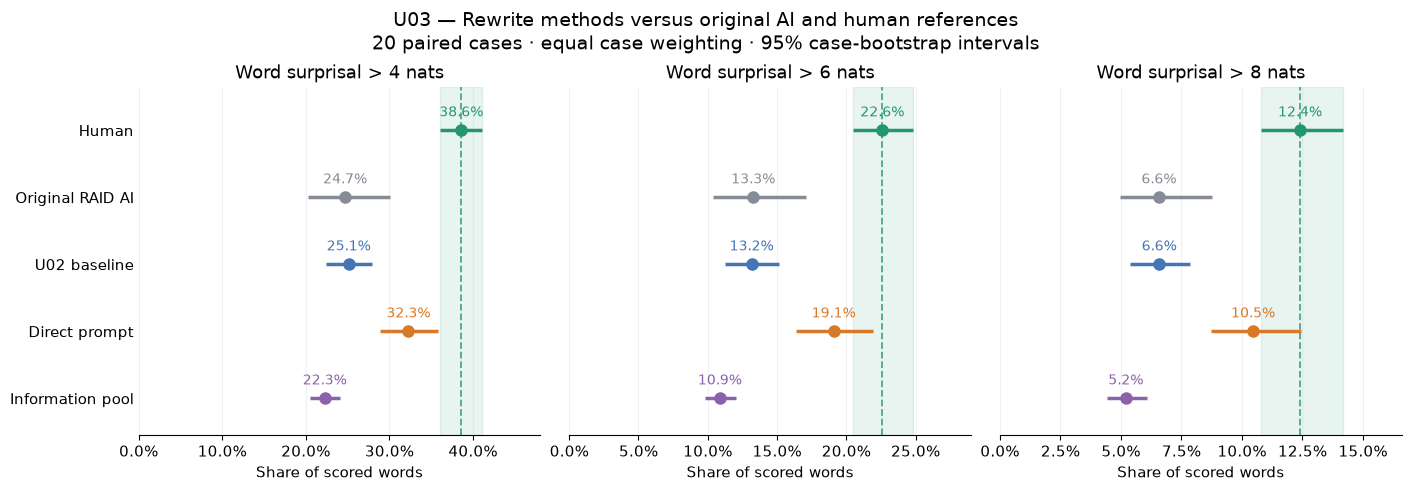

Mean tail shares:


,> 4 nats (%),> 6 nats (%),> 8 nats (%)
Human,38.603,22.597,12.400
Original RAID AI,24.701,13.279,6.570
U02 baseline,25.131,13.163,6.582
Direct prompt,32.275,19.086,10.460
Information pool,22.263,10.871,5.202


Signed difference from the human mean, in percentage points:


,> 4 nats (%),> 6 nats (%),> 8 nats (%)
Original RAID AI,-13.903,-9.318,-5.830
U02 baseline,-13.472,-9.434,-5.818
Direct prompt,-6.328,-3.511,-1.940
Information pool,-16.340,-11.726,-7.198


Saved figures: ../results/causal/U03_INFO_POOL_ALL20_GENERAL_v2/comparison_reused_u02
All 20 cases retained, including token-capped outputs.
Intervals describe case variability, not variability across generation seeds.


In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

graph_dir = POOL_OUT / "comparison_reused_u02"
panel = pd.read_parquet(graph_dir / "generations.parquet")
case_ids = run_cohort.case_id.astype(str).tolist()
assert len(case_ids) == len(set(case_ids)) == 20

order = ["HUMAN", "OG", "BASELINE", "DIRECT_PROMPT", "INFO_POOL"]
labels = ["Human", "Original RAID AI", "U02 baseline", "Direct prompt", "Information pool"]
colors = ["#23966F", "#858C96", "#4575B4", "#D77927", "#8A62AA"]
metrics = ["P_S_gt_4", "P_S_gt_6", "P_S_gt_8"]

# Resolve paired human references explicitly; no matching by title or similarity.
def raid_source_key(value):
    value = str(value)
    return value.split("raid:", 1)[1] if "raid:" in value else value

plot_corpus = pd.read_parquet(
    ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
)
human_rows = plot_corpus.loc[plot_corpus["label"].eq(0)].copy()
human_rows["_source_key"] = human_rows["source_id"].map(raid_source_key)

texts = []
for src in run_cohort.itertuples(index=False):
    cid = str(src.case_id)
    hit = human_rows.loc[
        human_rows["_source_key"].eq(raid_source_key(src.source_id))
        & human_rows.domain.astype(str).eq(str(src.domain))
    ]
    assert len(hit) == 1, (
        f"{cid}: expected one paired human reference; found {len(hit)}."
    )
    human_text = hit.iloc[0]["text"]
    assert isinstance(human_text, str) and human_text.strip()

    texts.extend([
        dict(case_id=cid, domain=str(src.domain),
             arm="HUMAN", text=human_text),
        dict(case_id=cid, domain=str(src.domain),
             arm="OG", text=str(src.previous_ai)),
    ])

    for arm in order[2:]:
        match = panel.loc[
            panel.case_id.astype(str).eq(cid)
            & panel.arm.eq(arm)
            & panel.replicate.eq(0)
        ]
        assert len(match) == 1, f"{cid}: missing/duplicate {arm}"
        texts.append(dict(
            case_id=cid, domain=str(src.domain), arm=arm,
            text=match.iloc[0]["generated_text"],
        ))

# Reuse the comparison cell's text-keyed score cache.
score_dir = graph_dir / "scores"
score_dir.mkdir(exist_ok=True)
scorer_spec = dict(
    model=QWEN_ID,
    revision=getattr(pool_qwen_model.config, "_commit_hash", None),
    convention="U03_regex_overlap_sum_v1",
    transformers=transformers.__version__,
)

records = []
for i, item in enumerate(texts, 1):
    spec = dict(text_sha=sha_text(item["text"]), scorer=scorer_spec)
    path = score_dir / f"{fingerprint(spec)}.json"

    if path.exists():
        cached = json.loads(path.read_text())
        assert cached["spec"] == spec
        scores = cached["metrics"]
    else:
        print(f"Scoring {i}/{len(texts)}: {item['case_id']} | {item['arm']}",
              flush=True)
        words = pool_word_surprisal(item["text"])
        values = np.array([s for _, _, s in words if np.isfinite(s)])
        assert len(values), f"No scored words: {item['case_id']} {item['arm']}"
        scores = dict(
            words=len(words), scored_words=len(values),
            **{f"P_S_gt_{t}": float(np.mean(values > t))
               for t in (4, 6, 8)},
        )
        atomic_json(path, dict(spec=spec, metrics=scores))

    records.append({
        k: item[k] for k in ("case_id", "domain", "arm")
    } | {m: scores[m] for m in metrics})

u03_plot_scores = pd.DataFrame(records)
u03_plot_scores.to_csv(graph_dir / "five_group_scores.csv", index=False)

# Shape: 20 cases × 5 groups × 3 thresholds.
# Resample the same case indices for every group to preserve pairing.
arrays = []
for metric in metrics:
    wide = u03_plot_scores.pivot(
        index="case_id", columns="arm", values=metric
    ).reindex(index=case_ids, columns=order)
    assert wide.notna().all().all()
    arrays.append(wide.to_numpy())

values = 100 * np.stack(arrays, axis=2)
means = values.mean(axis=0)
rng = np.random.default_rng(20260919)
indices = rng.integers(0, len(case_ids), size=(10000, len(case_ids)))
boot_means = values[indices].mean(axis=1)
lower, upper = np.quantile(boot_means, [0.025, 0.975], axis=0)

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "pdf.fonttype": 42,
}):
    fig, axes = plt.subplots(
        1, 3, figsize=(14, 4.8), sharey=True, layout="constrained"
    )
    y = np.arange(len(order))

    for j, (ax, threshold) in enumerate(zip(axes, (4, 6, 8))):
        # Human mean and confidence interval as a visual reference.
        ax.axvspan(lower[0, j], upper[0, j],
                   color=colors[0], alpha=0.10, zorder=0)
        ax.axvline(means[0, j], color=colors[0],
                   linestyle="--", linewidth=1.3, alpha=0.8)

        for k, color in enumerate(colors):
            ax.hlines(y[k], lower[k, j], upper[k, j],
                      color=color, linewidth=2.5)
            ax.plot(means[k, j], y[k], "o", color=color, markersize=8)
            ax.annotate(
                f"{means[k, j]:.1f}%",
                (means[k, j], y[k]),
                xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=10, color=color,
            )

        ax.set_title(f"Word surprisal > {threshold} nats")
        ax.set_xlabel("Share of scored words")
        ax.xaxis.set_major_formatter(PercentFormatter(100))
        ax.set_xlim(0, max(upper[:, j]) * 1.17)
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
        ax.set_ylim(len(order) - 0.45, -0.65)
        ax.grid(axis="x", alpha=0.18)
        ax.tick_params(axis="y", length=0)

    fig.suptitle(
        "U03 — Rewrite methods versus original AI and human references\n"
        "20 paired cases · equal case weighting · 95% case-bootstrap intervals",
        fontsize=14,
    )
    fig.savefig(graph_dir / "U03_five_group_comparison.png",
                dpi=300, bbox_inches="tight")
    fig.savefig(graph_dir / "U03_five_group_comparison.pdf",
                bbox_inches="tight")
    plt.show()

mean_table = pd.DataFrame(
    means, index=labels, columns=["> 4 nats (%)", "> 6 nats (%)", "> 8 nats (%)"]
)
print("Mean tail shares:")
display(mean_table.round(3))

print("Signed difference from the human mean, in percentage points:")
human_gap = mean_table.subtract(mean_table.loc["Human"])
display(human_gap.drop(index="Human").round(3))

mean_table.to_csv(graph_dir / "five_group_means_percent.csv")
human_gap.to_csv(graph_dir / "five_group_human_gap_pp.csv")

print("Saved figures:", graph_dir)
print("All 20 cases retained, including token-capped outputs.")
print("Intervals describe case variability, not variability across generation seeds.")